# A tour of `lefsim`

`lefsim` simulates loop-extrusion factors (LEFs) on a 1D lattice with CTCF
boundary elements, using an exact event-driven (Gibson–Bruck) engine written in
Rust. From Python, results arrive as **Arrow** data, so they drop straight into
polars, pyarrow, pandas or duckdb, and long runs can be **streamed** instead of
held in memory.

This notebook builds a lattice with a few TADs, runs it, and looks at the
result from several angles: leg trajectories, a ChIP-like occupancy profile,
where loops are anchored, loop sizes, the event log, and a streamed run far too
large to materialize.

**Running it.** From `crates/lefsim-py`:

```
uv venv && uv pip install maturin ipykernel matplotlib polars pyarrow duckdb
maturin develop --uv --release
```

then pick that `.venv` as the notebook kernel.

In [1]:
import time

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from matplotlib.colors import LinearSegmentedColormap, LogNorm

import lefsim

# Plot styling: quiet chrome, one blue for "all", orange for emphasis,
# and a single-hue blue ramp for magnitudes.
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE = "#2a78d6", "#eb6834"
BLUES = LinearSegmentedColormap.from_list(
    "blues", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"]
)
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 10,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": MUTED, "ytick.labelcolor": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "lines.linewidth": 2, "legend.frameon": False, "legend.labelcolor": INK2,
    "font.family": "sans-serif", "font.sans-serif": ["Helvetica Neue", "Arial", "DejaVu Sans"],
    "figure.dpi": 110,
})
print("lefsim", lefsim.__version__)

lefsim 0.1.0


## 1. A lattice with TADs

3,000 sites split into five TADs by four boundaries. Each boundary is a
**convergent CTCF pair**: the site ending the TAD on its left captures legs
arriving from the left, and the next site, starting the TAD on its right,
captures legs arriving from the right. A leg that slips through the first CTCF
(probability 1 − strength) meets the second one from its eviction side.

Twenty LEFs are placed at random non-CTCF sites. Captured LEFs live longer
(`respawn_rate_captured` is 5× slower than `respawn_rate`).

In [2]:
N_SITES = 3_000
BOUNDARIES = [600, 1300, 1800, 2500]

ctcf_sites, ctcf_sides = [], []
for b in BOUNDARIES:
    ctcf_sites += [b, b + 1]
    ctcf_sides += ["left", "right"]

params = dict(
    ctcf_sites=ctcf_sites,
    ctcf_captures_from=ctcf_sides,
    ctcf_strength=0.8,
    n_lefs=20,
    step_rate=1.0,
    respawn_rate=0.002,
    respawn_rate_captured=0.0004,
)
sim = lefsim.Sim(N_SITES, seed=1, **params)
sim

lefsim.Sim(n_sites=3000, n_lefs=20, time=0, event_count=0)

Everything that stays fixed during a run is available as tables from
`sim.meta()`: the lattice, the CTCFs, and the id mappings between LEFs and legs.

In [3]:
meta = sim.meta()
pl.DataFrame(meta["ctcfs"])

site,captures_from,strength
u32,cat,f64
600,"""Left""",0.8
601,"""Right""",0.8
1300,"""Left""",0.8
1301,"""Right""",0.8
1800,"""Left""",0.8
1801,"""Right""",0.8
2500,"""Left""",0.8
2501,"""Right""",0.8


## 2. Run and record

`run_until` fires every event up to `t_end`. With `dt=` it records a snapshot
of every LEF on a regular time grid. Snapshots are exact, not interpolated,
because state only changes at events. With `events=True` it also logs every
state change. The run releases the GIL and responds to Ctrl-C.

In [4]:
t = time.perf_counter()
rec = sim.run_until(50_000.0, dt=5.0, events=True)
elapsed = time.perf_counter() - t
print(f"{rec.events_fired:,} events in {elapsed:.2f} s ({rec.events_fired / elapsed / 1e6:.1f} M events/s)")
rec

405,256 events in 0.06 s (7.2 M events/s)


lefsim.Recording(events_fired=405256, time=50000, stopped="reached_time", snapshots=yes, events=yes)

`rec.snapshots` is an Arrow batch; `pl.DataFrame` reads it without copying.
The default *wide* layout has one row per LEF per snapshot, with both legs side by side.
Mobility columns are categorical.

In [5]:
snaps = pl.DataFrame(rec.snapshots)
events = pl.DataFrame(rec.events)
snaps.head()

time,lef_id,left_pos,right_pos,left_mobility,right_mobility
f64,u32,u32,u32,cat,cat
0.0,0,422,422,"""Moving""","""Moving"""
0.0,1,856,856,"""Moving""","""Moving"""
0.0,2,2018,2018,"""Moving""","""Moving"""
0.0,3,2771,2771,"""Moving""","""Moving"""
0.0,4,1020,1020,"""Moving""","""Moving"""


Rows are ordered by snapshot, then `lef_id`, so any column reshapes to a
`(n_snapshots, n_lefs)` array:

In [6]:
left = snaps["left_pos"].to_numpy().reshape(-1, sim.n_lefs)
left.shape

(10001, 20)

## 3. Leg trajectories

Each leg's position over a 4,000-unit window. Pairs of legs fan out from their
binding site, then run flat once a boundary holds them. One LEF is highlighted
from the moment it binds until both of its legs are held at a TAD's CTCFs.

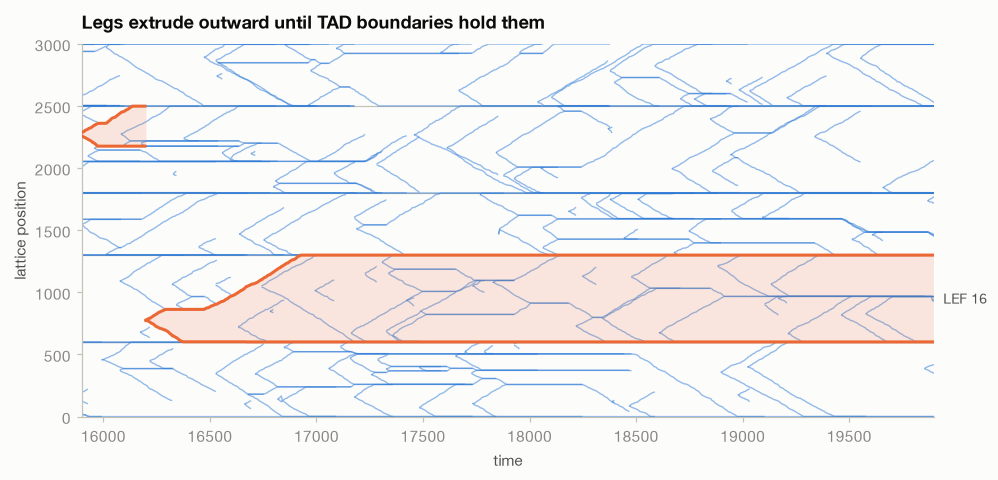

In [7]:
# Find the binding (a Respawn) that ends with both legs captured for longest,
# and center a window on it.
fully_held = snaps.filter((pl.col("left_mobility") == "Captured") & (pl.col("right_mobility") == "Captured"))
respawns = events.filter(pl.col("action") == "Respawn").unique(["time", "lef_id"]).sort("time")
best = (None, None, 0)
for lef, t_bind in respawns.select("lef_id", "time").iter_rows():
    t_next = respawns.filter((pl.col("lef_id") == lef) & (pl.col("time") > t_bind))["time"].min() or rec.time
    n_held = fully_held.filter((pl.col("lef_id") == lef) & pl.col("time").is_between(t_bind, t_next)).height
    if n_held > best[2]:
        best = (lef, t_bind, n_held)
focus, t_bind, _ = best

T0 = round(t_bind) - 300
T1 = T0 + 4_000
window = snaps.filter(pl.col("time").is_between(T0, T1))

def broken(t, x, jump=40):
    # Break the line where a leg jumps (a respawn) instead of drawing a vertical stroke.
    t, x = np.asarray(t, float), np.asarray(x, float)
    cut = np.flatnonzero(np.abs(np.diff(x)) > jump) + 1
    return np.insert(t, cut, np.nan), np.insert(x, cut, np.nan)

fig, ax = plt.subplots(figsize=(10, 4.4))
for b in BOUNDARIES:
    ax.axhline(b + 0.5, color=AXIS, lw=0.8, zorder=1)
for (lef,), g in window.group_by("lef_id", maintain_order=True):
    hl = lef == focus
    for col in ("left_pos", "right_pos"):
        ax.plot(*broken(g["time"], g[col]), color=ORANGE if hl else BLUE,
                lw=2 if hl else 0.9, alpha=1 if hl else 0.5, zorder=4 if hl else 2)
g = window.filter(pl.col("lef_id") == focus)
ax.fill_between(g["time"], g["left_pos"], g["right_pos"], step="post", color=ORANGE, alpha=0.15, lw=0, zorder=3)
ax.annotate(f"LEF {focus}", (T1, (g["left_pos"][-1] + g["right_pos"][-1]) / 2), xytext=(6, 0),
            textcoords="offset points", color=INK2, va="center", fontsize=9, annotation_clip=False)
ax.set(xlim=(T0, T1), ylim=(0, N_SITES), xlabel="time", ylabel="lattice position")
ax.set_title("Legs extrude outward until TAD boundaries hold them")
ax.grid(False)
plt.show()

## 4. Leg occupancy

Averaging leg positions over the run (after a short burn-in) gives a
profile like cohesin ChIP-seq: sharp accumulation at the CTCF pairs (marked
◀▶, pointing toward the side each one captures from), and at the lattice ends,
where legs simply stop.

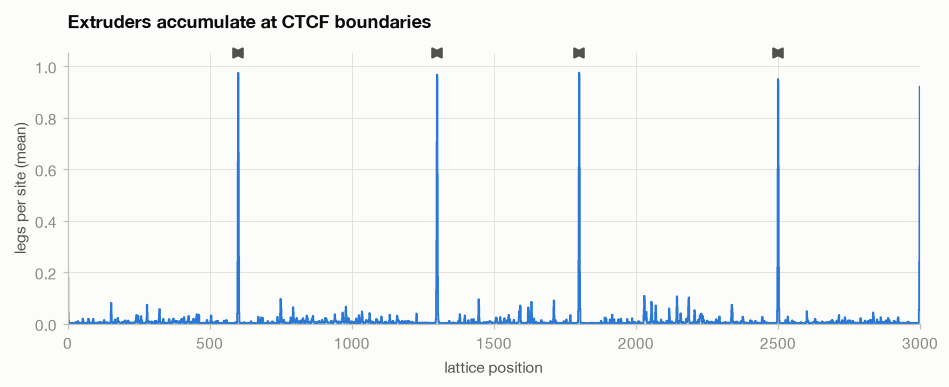

In [8]:
BURN_IN = 5_000
settled = snaps.filter(pl.col("time") >= BURN_IN)
n_snapshots = settled["time"].n_unique()
legs = np.concatenate([settled["left_pos"].to_numpy(), settled["right_pos"].to_numpy()])
occupancy = np.bincount(legs, minlength=N_SITES) / n_snapshots

def mark_ctcfs(ax, y):
    lo, hi = ax.get_xlim()
    for site, side in zip(ctcf_sites, ctcf_sides):
        if lo <= site <= hi:
            ax.plot(site, y, marker="<" if side == "left" else ">", color=INK2, ms=6, clip_on=False, zorder=5)

fig, ax = plt.subplots(figsize=(10, 3.2))
x = np.arange(N_SITES)
ax.fill_between(x, occupancy, step="mid", color=BLUE, alpha=0.18, lw=0)
ax.step(x, occupancy, where="mid", color=BLUE, lw=1.2)
top = occupancy.max() * 1.08
ax.set(xlim=(0, N_SITES), ylim=(0, top), xlabel="lattice position", ylabel="legs per site (mean)")
mark_ctcfs(ax, top)
ax.set_title("Extruders accumulate at CTCF boundaries", pad=16)
plt.show()

## 5. Where loops are anchored

Every snapshot gives each LEF's loop as a pair `(left anchor, right anchor)`.
A 2D histogram of those pairs (log color) shows three things:

- **Insulation.** Almost no loops span a boundary; mass stays inside the TAD triangles.
- **Stripes.** The dark top edge of each triangle is loops with the right leg
  held at the boundary while the left leg keeps extruding, the model's
  analogue of Hi-C stripes.
- **Corners.** Where the two edges meet, both legs are held: a whole-TAD loop.

This is loop anchoring, not a contact map. It is what a contact map's dots and
stripes would be built from.

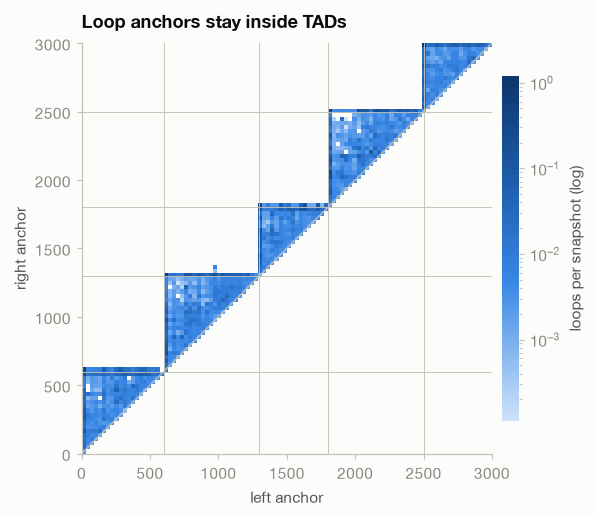

In [9]:
bins = np.arange(0, N_SITES + 30, 30)
H, _, _ = np.histogram2d(settled["left_pos"].to_numpy(), settled["right_pos"].to_numpy(), bins=[bins, bins])
H = np.ma.masked_where(H == 0, H) / n_snapshots

fig, ax = plt.subplots(figsize=(5.8, 5.1))
im = ax.pcolormesh(bins, bins, H.T, cmap=BLUES, norm=LogNorm(), rasterized=True)
for b in BOUNDARIES:
    ax.axvline(b, color=AXIS, lw=0.6)
    ax.axhline(b, color=AXIS, lw=0.6)
ax.plot([0, N_SITES], [0, N_SITES], color=AXIS, lw=0.8)
ax.set(xlim=(0, N_SITES), ylim=(0, N_SITES), aspect="equal", xlabel="left anchor", ylabel="right anchor")
ax.grid(False)
cb = fig.colorbar(im, ax=ax, shrink=0.8, pad=0.02)
cb.set_label("loops per snapshot (log)", color=INK2)
cb.outline.set_visible(False)
cb.ax.tick_params(colors=AXIS, labelcolor=MUTED)
ax.set_title("Loop anchors stay inside TADs")
plt.show()

## 6. Loop sizes

Loops that are still growing have a broad size distribution. Once a boundary
holds one leg, sizes pile up at the **full TAD sizes** as the other leg reaches
the opposite boundary.

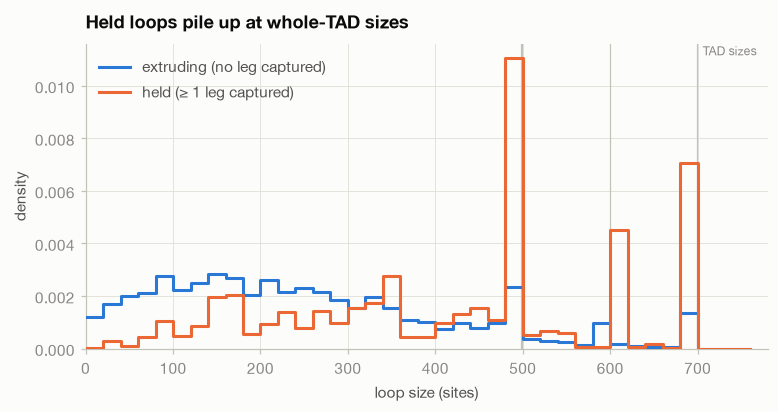

In [10]:
settled = settled.with_columns(
    size=pl.col("right_pos").cast(pl.Int64) - pl.col("left_pos").cast(pl.Int64),
    held=(pl.col("left_mobility") == "Captured") | (pl.col("right_mobility") == "Captured"),
)
tad_edges = [0] + [b + 1 for b in BOUNDARIES], BOUNDARIES + [N_SITES - 1]
tad_sizes = sorted({hi - lo for lo, hi in zip(*tad_edges)})

fig, ax = plt.subplots(figsize=(8, 3.6))
edges = np.arange(0, 800, 20)
for s in tad_sizes:
    ax.axvline(s, color=AXIS, lw=0.8, zorder=1)
ax.text(tad_sizes[-1], 1.0, "  TAD sizes", transform=ax.get_xaxis_transform(), color=MUTED, fontsize=8, va="top")
for held, color, label in [(False, BLUE, "extruding (no leg captured)"), (True, ORANGE, "held (≥ 1 leg captured)")]:
    h, _ = np.histogram(settled.filter(pl.col("held") == held)["size"], bins=edges, density=True)
    ax.step(edges[:-1], h, where="post", color=color, lw=2, label=label, zorder=3)
ax.set(xlim=(0, 780), ylim=(0, None), xlabel="loop size (sites)", ylabel="density")
ax.legend(loc="upper left")
ax.set_title("Held loops pile up at whole-TAD sizes")
plt.show()

## 7. The event log

`events=True` records one row per leg changed by each event: a `Step` moves one
leg, and a `Respawn` places both. `mobility` is the leg's state *after* the
event, so capture and eviction counts come from a single group-by.

In [11]:
events.head()

time,leg_id,lef_id,pos,mobility,action
f64,u32,u32,u32,cat,cat
0.036329,30,15,2342,"""Moving""","""Step"""
0.075667,37,18,464,"""Moving""","""Step"""
0.126268,33,16,1046,"""Moving""","""Step"""
0.1295,36,18,462,"""Moving""","""Step"""
0.191021,26,13,2480,"""Moving""","""Step"""


In [12]:
(
    events.group_by("action", "mobility")
    .len()
    .sort("action", "mobility")
)

action,mobility,len
cat,cat,u32
"""Respawn""","""Moving""",3026
"""Step""","""Captured""",149
"""Step""","""Evicted""",8
"""Step""","""Moving""",403586


Evictions (a leg arriving at a CTCF from its non-capture side) trigger an
immediate respawn at the same instant, so the snapshots never show an
`Evicted` leg. The event log is the only place those events are visible.

In [13]:
assert "Evicted" not in snaps["left_mobility"].to_list() + snaps["right_mobility"].to_list()
print("evicted legs in the event log:", events.filter(pl.col("mobility") == "Evicted").height)

evicted legs in the event log: 8


The same snapshots in the *long* layout have one row per leg, which is
convenient for per-leg group-bys. Both layouts come straight from Rust.

In [14]:
pl.DataFrame(sim.snapshot(layout="long")).head(6)

time,leg_id,lef_id,facing,pos,mobility
f64,u32,u32,cat,u32,cat
50000.0,0,0,"""Left""",2502,"""Moving"""
50000.0,1,0,"""Right""",2759,"""Moving"""
50000.0,2,1,"""Left""",1843,"""Moving"""
50000.0,3,1,"""Right""",2163,"""Moving"""
50000.0,4,2,"""Left""",613,"""Moving"""
50000.0,5,2,"""Right""",861,"""Moving"""


## 8. Streaming a long run

The occupancy profile above is noisy at single-site resolution. For finer
statistics we want a much longer run: **2 million time units**, sampled every
time unit, is ~80 million leg-rows (~1.8 GB if materialized).

`sim.stream(...)` hands the simulation to a lazy Arrow stream that runs *as it
is read*, one chunk at a time. duckdb aggregates it on the fly, so memory stays
bounded. (A stream consumes its `Sim`, so we build a fresh one.)

In [15]:
long_sim = lefsim.Sim(N_SITES, seed=2, **params)
stream = long_sim.stream(2_000_000.0, dt=1.0, layout="long", chunk_size=50_000)

t = time.perf_counter()
per_site = duckdb.sql(f'''
    select pos, count(*) as n
    from stream
    where time >= {BURN_IN}
    group by pos
''').pl()
elapsed = time.perf_counter() - t

rows = per_site["n"].sum()
print(f"aggregated {rows:,} leg-rows (~{rows * 22 / 1e9:.1f} GB if materialized) in {elapsed:.1f} s")

aggregated 79,800,040 leg-rows (~1.8 GB if materialized) in 2.7 s


In [16]:
n_long = rows // (2 * sim.n_lefs)  # snapshots after burn-in
occupancy_long = np.zeros(N_SITES)
occupancy_long[per_site["pos"].to_numpy()] = per_site["n"].to_numpy() / n_long

cv = lambda a: a.std() / a.mean()
print(f"TAD interior (sites 620-1280), coefficient of variation: "
      f"{cv(occupancy[620:1280]):.2f} in memory -> {cv(occupancy_long[620:1280]):.2f} streamed")

TAD interior (sites 620-1280), coefficient of variation: 1.36 in memory -> 0.48 streamed


Zooming in on one boundary (sites 1300/1301), on a log scale. The peak is big
enough to see even in the short run; the long run pins down its tails and the
flanks around it.

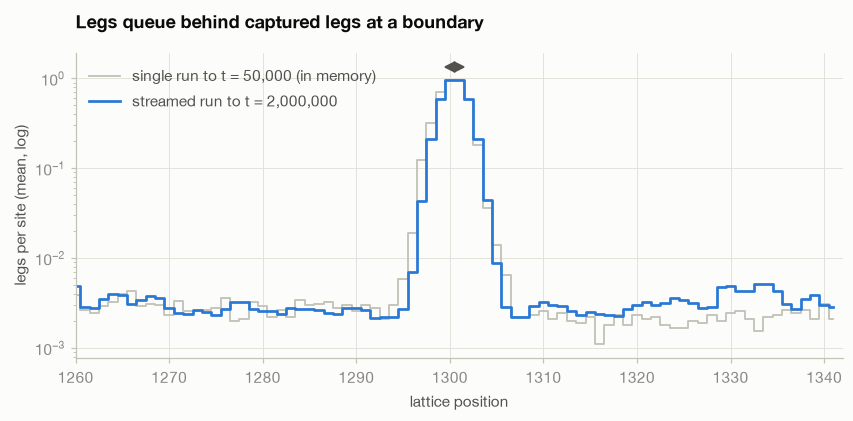

sites 1296-1305 (streamed): [0.007 0.043 0.209 0.597 0.96  0.959 0.592 0.21  0.044 0.009]


In [17]:
lo, hi = 1260, 1342
x = np.arange(lo, hi)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.step(x, np.where(occupancy[lo:hi] > 0, occupancy[lo:hi], np.nan), where="mid",
        color=AXIS, lw=1.2, label="single run to t = 50,000 (in memory)")
ax.step(x, occupancy_long[lo:hi], where="mid", color=BLUE, lw=1.8, label="streamed run to t = 2,000,000")
ax.set_yscale("log")
ax.set(xlim=(lo, hi), xlabel="lattice position", ylabel="legs per site (mean, log)")
mark_ctcfs(ax, ax.get_ylim()[1])
ax.legend(loc="upper left")
ax.set_title("Legs queue behind captured legs at a boundary", pad=16)
plt.show()

print("sites 1296-1305 (streamed):", np.round(occupancy_long[1296:1306], 3))

The boundary peak is a **queue**: occupancy falls off steeply on both sides of
the CTCF pair (about 0.96 → 0.6 → 0.2 → 0.04 per site), because legs pile up
behind a captured leg and can't step onto an occupied site. Just past the
queue, occupancy (~0.0025 per site) is about half its value ~100 sites deeper
into the TAD (~0.005). With ~220× more snapshots, the interior noise also drops
(the coefficient of variation above).

To keep the raw data instead, stream to Parquet the same way:
`duckdb.sql("copy (select * from stream) to 'run.parquet'")`.

## 9. Reproducibility

A seed fixes the whole run, bit for bit. That holds across Python and Rust,
and across native and WebAssembly builds. The test suites pin a golden hash of
a long run in both languages.

In [18]:
def run(seed):
    s = lefsim.Sim(N_SITES, seed=seed, **params)
    return pl.DataFrame(s.run_until(5_000.0, dt=1.0).snapshots)

print("same seed, identical:", run(7).equals(run(7)))
print("different seed, identical:", run(7).equals(run(8)))

same seed, identical: True
different seed, identical: False
